# Risk-Adjusted Trend Following Strategy

Albert Yelken

This notebook evaluates the hypothesis of whether a Risk-Adjusted Trend Following strategy that longs an ETF if the shorter lookback window's Sharpe ratio crosses the longer lookback window's Sharpe Ratio with position sizing determined by forecast value can produce excess returns compared to SPY.

In [13]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [14]:
# Controlled Vars
ASSET_UNIVERSE = ['VGT', 'QTUM', 'XLK', 'FTEC', 'SMH', 'SOXX', 'IGM']

BACKTEST_START = '2021-01-01'
BACKTEST_END = '2026-01-01'

RISK_FREE_RATE = 0.00017857

In [15]:
# Independent Vars
LONGER_WINDOW_DAYS = 64
SHORTER_WINDOW_DAYS = 16

## Methodology

### Data Collection

In [ ]:
data = yf.download(
    ASSET_UNIVERSE,
    start=pd.to_datetime(BACKTEST_START) - pd.DateOffset(years=5),
    end=BACKTEST_END,
    auto_adjust=True
)

[*********************100%***********************]  6 of 7 completed


### Rolling Sharpe Ratio Calculation

In [17]:
def calculate_rolling_returns(daily_returns, window):
    return daily_returns.rolling(window=window).sum().dropna()

def calculate_rolling_stddev(daily_returns, window):
    return daily_returns.rolling(window=window).std().dropna()

def calculate_rolling_sharpe(rolling_returns, window, stddev):
    average_daily_returns_over_window = rolling_returns/window
    return ((average_daily_returns_over_window-RISK_FREE_RATE)/stddev)

In [18]:
daily_returns = ((data["Close"]/data["Close"].shift(1)))-1

longer_window_rolling_returns = calculate_rolling_returns(daily_returns, LONGER_WINDOW_DAYS)
shorter_window_rolling_returns = calculate_rolling_returns(daily_returns, SHORTER_WINDOW_DAYS)

longer_window_rolling_stddev = calculate_rolling_stddev(daily_returns, LONGER_WINDOW_DAYS)
shorter_window_rolling_stddev = calculate_rolling_stddev(daily_returns, SHORTER_WINDOW_DAYS)

longer_window_rolling_sharpe = calculate_rolling_sharpe(longer_window_rolling_returns, LONGER_WINDOW_DAYS, longer_window_rolling_stddev)
shorter_window_rolling_sharpe = calculate_rolling_sharpe(shorter_window_rolling_returns, SHORTER_WINDOW_DAYS, shorter_window_rolling_stddev)

### Signal Generation

In [19]:
unscaled_forecast = (shorter_window_rolling_sharpe - longer_window_rolling_sharpe).shift(1).dropna()

historical_abs_forecast = (unscaled_forecast.abs().expanding(min_periods=64).mean().mean(axis=1).shift(1))

forecast_scale_multiplier = 10 / historical_abs_forecast

forecast = (unscaled_forecast.mul(forecast_scale_multiplier, axis=0).clip(lower=0, upper=20))
forecast = forecast[(forecast.index >= BACKTEST_START) & (forecast.index < BACKTEST_END)]

### Portfolio Construction

In [20]:
number_of_assets = len(ASSET_UNIVERSE)

daily_asset_weights = forecast / (20 * number_of_assets)

weight_adjusted_daily_returns = (
    daily_returns * daily_asset_weights
).dropna()

daily_portfolio_returns = weight_adjusted_daily_returns.sum(axis=1)

## Results

### Cumulative Performance

In [21]:
portfolio_returns = (1 + daily_portfolio_returns).cumprod() - 1

### Benchmark Comparison

In [ ]:
spy_data = yf.download(
    "SPY",
    start=BACKTEST_START,
    end=BACKTEST_END,
    auto_adjust=True
)

spy_prices = spy_data["Close"].squeeze()
spy_daily_returns = spy_prices.pct_change()

aligned_returns = pd.concat(
    [daily_portfolio_returns, spy_daily_returns],
    axis=1,
    keys=["Strategy", "SPY"]
).dropna()

aligned_cumulative_returns = (
    (1 + aligned_returns).cumprod() - 1
)

[*********************100%***********************]  1 of 1 completed


### Performance Metrics

In [ ]:
def calculate_metrics(returns):
    returns = returns.dropna()

    cumulative_growth = (1 + returns).cumprod()
    years = len(returns) / 252

    cagr = cumulative_growth.iloc[-1] ** (1 / years) - 1
    volatility = returns.std() * np.sqrt(252)

    sharpe = (
        (returns.mean() - RISK_FREE_RATE) /
        returns.std() * np.sqrt(252)
    )

    drawdown = cumulative_growth / cumulative_growth.cummax() - 1
    max_drawdown = drawdown.min()

    return {
        "CAGR": cagr,
        "Annualized Volatility": volatility,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": max_drawdown
    }


performance_metrics = pd.DataFrame({
    "Strategy": calculate_metrics(aligned_returns["Strategy"]),
    "SPY": calculate_metrics(aligned_returns["SPY"])
})

performance_metrics

,Strategy,SPY
CAGR,0.033351,0.147240
Annualized Volatility,0.096927,0.171110
Sharpe Ratio,-0.077501,0.625294
Max Drawdown,-0.141279,-0.244964


### Performance Visualization

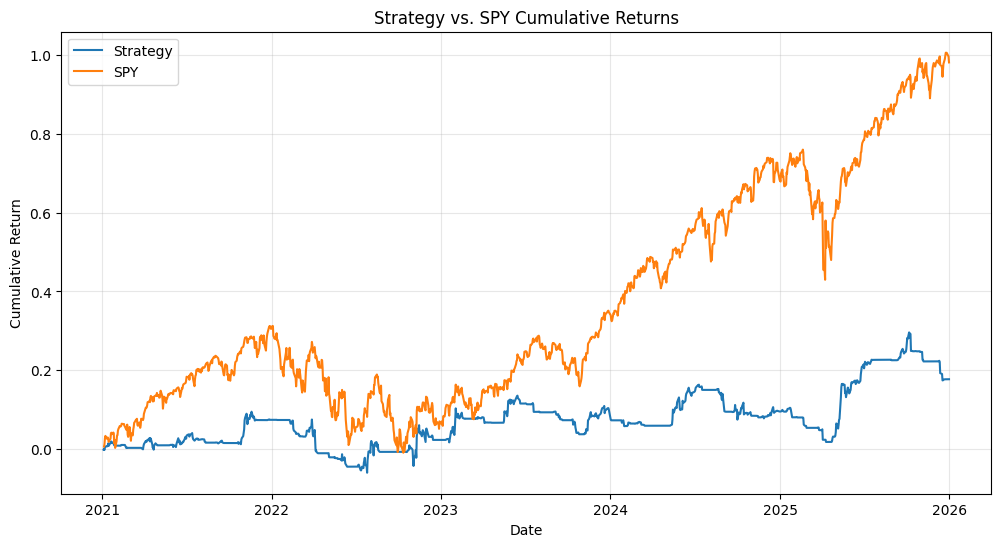

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    aligned_cumulative_returns["Strategy"],
    label="Strategy"
)

plt.plot(
    aligned_cumulative_returns["SPY"],
    label="SPY"
)

plt.title("Strategy vs. SPY Cumulative Returns")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

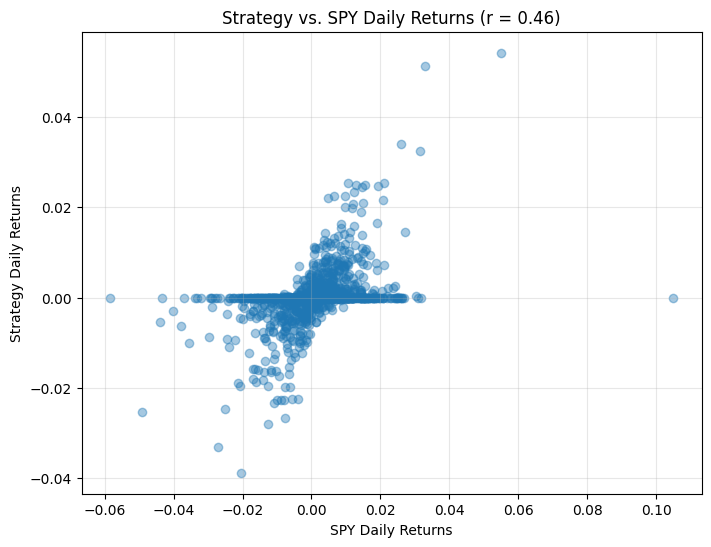

In [ ]:
correlation = aligned_returns["Strategy"].corr(
    aligned_returns["SPY"]
)

plt.figure(figsize=(8, 6))

plt.scatter(
    aligned_returns["SPY"],
    aligned_returns["Strategy"],
    alpha=0.4
)

plt.title(
    f"Strategy vs. SPY Daily Returns (r = {correlation:.2f})"
)
plt.xlabel("SPY Daily Returns")
plt.ylabel("Strategy Daily Returns")
plt.grid(alpha=0.3)
plt.show()

## Discussion & Limitations

This backtest evaluates a risk-adjusted trend-following strategy across seven technology-focused ETFs.

The strategy assumes frictionless execution and does not account for transaction costs, slippage, or management fees.

Additionally, the selected ETFs exhibit overlapping sector exposure, which may limit diversification benefits.

Future research could incorporate transaction costs, out-of-sample testing, and sensitivity analysis of the rolling Sharpe ratio lookback windows.